## 1: Atur Lokasi File Dataset

In [ ]:
import os

FOLDER_DATA = 'data'
NAMA_FILE = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
LOKASI_FILE = os.path.join(FOLDER_DATA, NAMA_FILE)

# Cek apakah file ditemukan
if os.path.exists(LOKASI_FILE):
    print(f'File dataset ditemukan di: {LOKASI_FILE}')
else:
    print(f'File TIDAK ditemukan: {LOKASI_FILE}')

File dataset ditemukan di: data\WA_Fn-UseC_-Telco-Customer-Churn.csv


## Import Library


In [ ]:
# Import semua library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings

warnings.filterwarnings('ignore')  # sembunyikan pesan peringatan agar output lebih bersih

print('Semua library berhasil diimport!')

Semua library berhasil diimport!


---
## FASE 1: Business Understanding

### Latar Belakang
Perusahaan telekomunikasi menghadapi masalah customer churn - pelanggan yang berhenti menggunakan layanan. Biaya akuisisi pelanggan baru jauh lebih mahal daripada mempertahankan pelanggan yang ada.

### Tujuan Bisnis
- Mengidentifikasi pelanggan yang berpotensi churn sebelum mereka benar-benar berhenti
- Memungkinkan tim marketing untuk melakukan intervensi tepat waktu

### Tujuan Data Mining
- Membangun model klasifikasi menggunakan algoritma KNN
- Target variabel: Churn (Yes = berhenti, No = tetap)
- Mengukur akurasi model

### Kriteria Sukses
- Akurasi model ≥ 70%
- Model mampu mengklasifikasikan data baru secara otomatis

## FASE 2: Data Understanding

### 2.1 Load Dataset

In [ ]:
# 2.1 Baca dataset
dataset = pd.read_csv(LOKASI_FILE)

print('Dataset berhasil dimuat!')
print(f'Jumlah baris : {dataset.shape[0]}')
print(f'Jumlah kolom : {dataset.shape[1]}')

print('\nDaftar kolom:')
for nomor, nama_kolom in enumerate(dataset.columns, 1):
    print(f'{nomor:2d}. {nama_kolom}')

Dataset berhasil dimuat!
Jumlah baris : 7043
Jumlah kolom : 21

Daftar kolom:
 1. customerID
 2. gender
 3. SeniorCitizen
 4. Partner
 5. Dependents
 6. tenure
 7. PhoneService
 8. MultipleLines
 9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


In [ ]:
# Preview 5 baris pertama
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Informasi tipe data
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Distribusi Churn:
No  : 5174 (73.5%)
Yes : 1869 (26.5%)


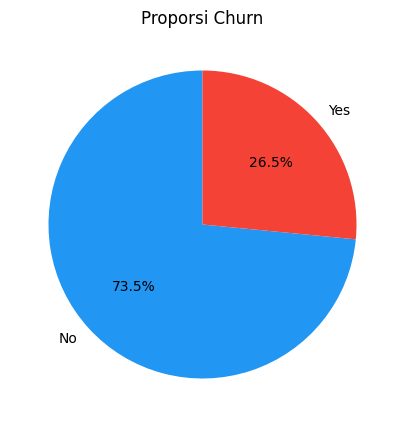

In [ ]:
# Hitung distribusi churn
jumlah = dataset['Churn'].value_counts()

# Tampilkan jumlah & persentase
print('Distribusi Churn:')
print(f'No  : {jumlah["No"]} ({jumlah["No"] / len(dataset) * 100:.1f}%)')
print(f'Yes : {jumlah["Yes"]} ({jumlah["Yes"] / len(dataset) * 100:.1f}%)')

# Pie chart
plt.figure(figsize=(5, 5))
plt.pie(
    jumlah,
    labels=['No', 'Yes'],
    autopct='%1.1f%%',
    colors=['#2196F3', '#F44336'],
    startangle=90
)
plt.title('Proporsi Churn')
plt.show()

### 2.2 Cek Missing Value

In [ ]:
# Cek missing value (nilai kosong/NaN) pada setiap kolom
print('Jumlah missing value per kolom:')
print(dataset.isnull().sum())

# Cek nilai spasi kosong pada kolom TotalCharges
spasi_total_charges = (dataset['TotalCharges'].str.strip() == '').sum()
print(f'\nNilai spasi kosong pada TotalCharges: {spasi_total_charges}')

Jumlah missing value per kolom:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0

Nilai spasi kosong pada TotalCharges: 11


### 2.3 Cek Duplikat Data

In [ ]:
# Cek baris duplikat pada dataset
jumlah_duplikat = dataset.duplicated().sum()
print(f'Jumlah data duplikat: {jumlah_duplikat}')

Jumlah data duplikat: 0


### 2.4 Cek Outlier

Pengecekan Outlier (Metode IQR):
- tenure         : 0 outlier (Rentang wajar: -60.00 s/d 124.00)
- MonthlyCharges : 0 outlier (Rentang wajar: -46.02 s/d 171.38)
- TotalCharges   : 0 outlier (Rentang wajar: -4688.48 s/d 8884.67)


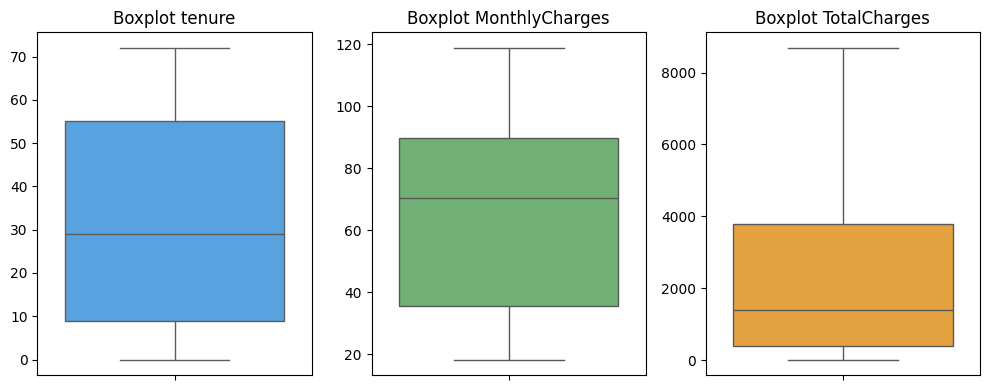

In [ ]:
# Cek outlier pada kolom numerik menggunakan metode IQR
kolom_numerik = ['tenure', 'MonthlyCharges']
data_numerik = dataset[kolom_numerik].copy()
data_numerik['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')

print('Pengecekan Outlier (Metode IQR):')
for kolom in data_numerik.columns:
    Q1 = data_numerik[kolom].quantile(0.25)
    Q3 = data_numerik[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    
    outliers = data_numerik[(data_numerik[kolom] < batas_bawah) | (data_numerik[kolom] > batas_atas)]
    print(f'- {kolom:15s}: {len(outliers)} outlier (Rentang wajar: {batas_bawah:.2f} s/d {batas_atas:.2f})')

# Visualisasi Boxplot untuk melihat sebaran data
plt.figure(figsize=(10, 4))
for i, kolom in enumerate(data_numerik.columns, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=data_numerik[kolom], color='#42A5F5')
    plt.title(f'Boxplot {kolom}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

##  FASE 3: Data Preparation

### 3.1 Encoding


In [ ]:
# Encoding atribut kategorikal ke nilai numerik

# Salinan dataset agar data asli tetap tersimpan
dataset_encoded = dataset.copy()

# Encoding kolom utama
dataset_encoded['InternetService'] = dataset_encoded['InternetService'].map({
    'No': 0, 'DSL': 1, 'Fiber optic': 2
})

dataset_encoded['Contract'] = dataset_encoded['Contract'].map({
    'Month-to-month': 0, 'One year': 1, 'Two year': 2
})

dataset_encoded['gender'] = dataset_encoded['gender'].map({
    'Female': 0, 'Male': 1
})

# Kolom biner (Yes/No)
kolom_biner = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for kolom in kolom_biner:
    dataset_encoded[kolom] = dataset_encoded[kolom].map({
        'No': 0, 'Yes': 1
    })

# MultipleLines
dataset_encoded['MultipleLines'] = dataset_encoded['MultipleLines'].map({
    'No phone service': 0, 'No': 1, 'Yes': 2
})

# Layanan internet
kolom_layanan_internet = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

for kolom in kolom_layanan_internet:
    dataset_encoded[kolom] = dataset_encoded[kolom].map({
        'No internet service': 0, 'No': 1, 'Yes': 2
    })

# Payment method
dataset_encoded['PaymentMethod'] = dataset_encoded['PaymentMethod'].map({
    'Electronic check': 0,
    'Mailed check': 1,
    'Bank transfer (automatic)': 2,
    'Credit card (automatic)': 3
})

print('Encoding selesai!')

# Tampilkan hasil
kolom_encoded = (
    kolom_biner
    + ['gender', 'MultipleLines', 'InternetService']
    + kolom_layanan_internet
    + ['Contract', 'PaymentMethod']
)

display(dataset_encoded[kolom_encoded].head())

print('\nNilai unik setelah encoding:')
for kolom in kolom_encoded:
    nilai_unik = sorted(dataset_encoded[kolom].dropna().unique().tolist())
    print(f'{kolom:25s}: {nilai_unik}')

Encoding selesai!


,Partner,Dependents,PhoneService,PaperlessBilling,gender,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaymentMethod
0,1,0,0,1,0,0,1,1,2,1,1,1,1,0,0
1,0,0,1,0,1,1,1,2,1,2,1,1,1,1,1
2,0,0,1,1,1,1,1,2,2,1,1,1,1,0,1
3,0,0,0,0,1,0,1,2,1,2,2,1,1,1,2
4,0,0,1,1,0,1,2,1,1,1,1,1,1,0,0



Nilai unik setelah encoding:
Partner                  : [0, 1]
Dependents               : [0, 1]
PhoneService             : [0, 1]
PaperlessBilling         : [0, 1]
gender                   : [0, 1]
MultipleLines            : [0, 1, 2]
InternetService          : [0, 1, 2]
OnlineSecurity           : [0, 1, 2]
OnlineBackup             : [0, 1, 2]
DeviceProtection         : [0, 1, 2]
TechSupport              : [0, 1, 2]
StreamingTV              : [0, 1, 2]
StreamingMovies          : [0, 1, 2]
Contract                 : [0, 1, 2]
PaymentMethod            : [0, 1, 2, 3]


## Pemilihan Atribut (Feature Selection)

Fitur yang dipilih = 'gender', 'SeniorCitizen', 'tenure', 'InternetService', 'Contract','MonthlyCharges', 'TotalCharges', 'Churn'

In [ ]:
# Pemilihan fitur dan pembersihan data
FITUR=['gender','SeniorCitizen','tenure','InternetService','Contract','MonthlyCharges','TotalCharges']
TARGET='Churn'

# Konversi TotalCharges ke numerik
dataset_encoded['TotalCharges']=pd.to_numeric(dataset_encoded['TotalCharges'],errors='coerce')

# Encoding target
dataset_encoded['Churn']=dataset_encoded['Churn'].map({'No':0,'Yes':1})

# Hapus missing value
dataset_bersih=dataset_encoded[FITUR+[TARGET]].dropna().reset_index(drop=True)

# Info singkat
print('Pemilihan atribut selesai!')
print(f'Fitur:{FITUR}')
print(f'Target:{TARGET}')
print(f'Total:{len(dataset_bersih)} data')
print(dataset_bersih['Churn'].value_counts())

# Statistik
dataset_bersih[FITUR].describe().round(4)

Pemilihan atribut selesai!
Fitur:['gender', 'SeniorCitizen', 'tenure', 'InternetService', 'Contract', 'MonthlyCharges', 'TotalCharges']
Target:Churn
Total:7032 data
Churn
0    5163
1    1869
Name: count, dtype: int64


,gender,SeniorCitizen,tenure,InternetService,Contract,MonthlyCharges,TotalCharges
count,7032.0000,7032.0000,7032.0000,7032.0000,7032.0000,7032.0000,7032.0000
mean,0.5047,0.1624,32.4218,1.2241,0.6886,64.7982,2283.3004
std,0.5000,0.3688,24.5453,0.7786,0.8329,30.0860,2266.7714
min,0.0000,0.0000,1.0000,0.0000,0.0000,18.2500,18.8000
25%,0.0000,0.0000,9.0000,1.0000,0.0000,35.5875,401.4500
50%,1.0000,0.0000,29.0000,1.0000,0.0000,70.3500,1397.4750
75%,1.0000,0.0000,55.0000,2.0000,1.0000,89.8625,3794.7375
max,1.0000,1.0000,72.0000,2.0000,2.0000,118.7500,8684.8000


### SPLITING DATA

In [ ]:
# Split data 80:20
from sklearn.model_selection import train_test_split

X_semua=dataset_bersih[FITUR]
y_semua=dataset_bersih[TARGET]
y_semua_biner = dataset_bersih['Churn']

X_train_raw,X_test_raw,y_train,y_test,y_train_biner,y_test_biner=train_test_split(
    X_semua,y_semua,y_semua_biner,test_size=0.2,random_state=42,stratify=y_semua
)

X_train_raw=X_train_raw.reset_index(drop=True)
X_test_raw=X_test_raw.reset_index(drop=True)
y_train=y_train.reset_index(drop=True)
y_test=y_test.reset_index(drop=True)
y_train_biner=y_train_biner.reset_index(drop=True)
y_test_biner=y_test_biner.reset_index(drop=True)

print('Split selesai!')
print(f'Total:{len(dataset_bersih)}')
print(f'Train:{len(X_train_raw)} | Test:{len(X_test_raw)}')
print(f'Train No:{(y_train==0).sum()} Yes:{(y_train==1).sum()}')
print(f'Test  No:{(y_test==0).sum()} Yes:{(y_test==1).sum()}')

display(X_train_raw.assign(Churn=y_train).head())
display(X_test_raw.assign(Churn=y_test).head())

Split selesai!
Total:7032
Train:5625 | Test:1407
Train No:4130 Yes:1495
Test  No:1033 Yes:374


,gender,SeniorCitizen,tenure,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
0,1,0,65,2,2,94.55,6078.75,0
1,1,0,26,1,0,35.75,1022.50,0
2,0,0,68,2,2,90.20,6297.65,0
3,1,0,3,2,0,84.30,235.05,0
4,0,0,49,1,0,40.65,2070.75,0


,gender,SeniorCitizen,tenure,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
0,0,0,59,1,2,75.95,4542.35,0
1,0,0,7,2,0,78.55,522.95,0
2,0,0,54,0,2,20.10,1079.45,0
3,0,0,2,0,0,20.65,38.70,1
4,0,0,71,2,2,105.15,7555.00,0


### Normalisasi

In [ ]:
# Normalisasi Min-Max
nilai_min=X_train_raw.min()
nilai_max=X_train_raw.max()

def normalisasi_minmax(data,nilai_min,nilai_max):
    return (data-nilai_min)/(nilai_max-nilai_min)

X_train=normalisasi_minmax(X_train_raw,nilai_min,nilai_max)
X_test=normalisasi_minmax(X_test_raw,nilai_min,nilai_max)

print('Normalisasi Min-Max selesai!')
print(f'Data Training:{len(X_train)} baris ternormalisasi')
print(f'Data Testing:{len(X_test)} baris ternormalisasi')

tabel_minmax=pd.DataFrame({'Min':nilai_min,'Max':nilai_max,'Range':nilai_max-nilai_min})
print('\nTabel Min & Max (dari data training):')
display(tabel_minmax.round(4))

print(f'\nData Training Ternormalisasi (5 dari {len(X_train)} baris):')
display(X_train.assign(Churn=y_train).head().round(5))

print(f'\nData Testing Ternormalisasi (5 dari {len(X_test)} baris):')
display(X_test.assign(Churn=y_test).head().round(5))

Normalisasi Min-Max selesai!
Data Training:5625 baris ternormalisasi
Data Testing:1407 baris ternormalisasi

Tabel Min & Max (dari data training):


,Min,Max,Range
gender,0.0,1.00,1.00
SeniorCitizen,0.0,1.00,1.00
tenure,1.0,72.00,71.00
InternetService,0.0,2.00,2.00
Contract,0.0,2.00,2.00
MonthlyCharges,18.4,118.65,100.25
TotalCharges,18.8,8684.80,8666.00



Data Training Ternormalisasi (5 dari 5625 baris):


,gender,SeniorCitizen,tenure,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
0,1.0,0.0,0.90141,1.0,1.0,0.75960,0.69928,0
1,1.0,0.0,0.35211,0.5,0.0,0.17307,0.11582,0
2,0.0,0.0,0.94366,1.0,1.0,0.71621,0.72454,0
3,1.0,0.0,0.02817,1.0,0.0,0.65736,0.02495,0
4,0.0,0.0,0.67606,0.5,0.0,0.22195,0.23678,0



Data Testing Ternormalisasi (5 dari 1407 baris):


,gender,SeniorCitizen,tenure,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
0,0.0,0.0,0.81690,0.5,1.0,0.57406,0.52199,0
1,0.0,0.0,0.08451,1.0,0.0,0.60000,0.05818,0
2,0.0,0.0,0.74648,0.0,1.0,0.01696,0.12239,0
3,0.0,0.0,0.01408,0.0,0.0,0.02244,0.00230,1
4,0.0,0.0,0.98592,1.0,1.0,0.86534,0.86963,0


## FASE 4: Modeling - Algoritma KNN



### 4.1 Konsep KNN

**K-Nearest Neighbor (KNN)** adalah algoritma klasifikasi yang:
1. Menghitung jarak antara data baru dengan semua data training
2. Memilih K data training dengan jarak terkecil (tetangga terdekat)
3. Melakukan **voting** — kelas mayoritas dari K tetangga = prediksi

### 4.2 Rumus Euclidean Distance

$$d(x, y) = \sqrt{\sum_{i=1}^{n}(x_i - y_i)^2}$$


In [ ]:
# Implementasi KNN dari scratch

def hitung_euclidean(titik_a,titik_b):
    # hitung jarak antar dua titik
    return np.sqrt(np.sum((np.array(titik_a)-np.array(titik_b))**2))

def prediksi_knn(X_train,y_train_label,X_test,k=3,verbose=False):
    daftar_prediksi=[]
    semua_detail=[]

    for i in range(len(X_test)):
        titik_uji=X_test.iloc[i].values  # data test

        semua_jarak=[]
        for j in range(len(X_train)):
            # hitung jarak ke semua data training
            jarak=hitung_euclidean(titik_uji,X_train.iloc[j].values)
            semua_jarak.append((j+1,jarak,y_train_label.iloc[j]))

        jarak_terurut=sorted(semua_jarak,key=lambda x:x[1])  # urutkan jarak
        k_tetangga=jarak_terurut[:k]  # ambil k terdekat

        suara=[t[2] for t in k_tetangga]
        hasil_voting=Counter(suara)  # voting mayoritas
        prediksi=hasil_voting.most_common(1)[0][0]
        daftar_prediksi.append(prediksi)

        if verbose:
            print(f'\nData Test ke-{i+1}:')
            print(f'{k} Tetangga Terdekat:')
            for rank,(no_tr,jarak,label) in enumerate(k_tetangga,1):
                print(f'Rank {rank}:Train#{no_tr}|Jarak={jarak:.6f}|Kelas={label}')
            print(f'Voting:{dict(hasil_voting)}→Prediksi:{prediksi}')

        semua_detail.append({
            'jarak_terurut':jarak_terurut,
            'k_tetangga':k_tetangga,
            'voting':hasil_voting,
            'prediksi':prediksi
        })

    return daftar_prediksi,semua_detail

print('Fungsi KNN siap!')

Fungsi KNN siap!


In [ ]:
# Detail perhitungan KNN untuk data testing ke-1
K = 5
print('='*65)
print(f'CONTOH DETAIL PERHITUNGAN KNN (K={K}) — Data Test ke-1')
print('='*65)

titik_test_1 = X_test.iloc[0].values  # ambil data test pertama
print(f'\nData Testing ke-1 (Ternormalisasi):')
for nama_fitur, nilai in zip(FITUR, titik_test_1):
    print(f"  {nama_fitur}' = {nilai:.6f}")
print(f'  Aktual Churn = {y_test.iloc[0]} ({"Churn" if y_test.iloc[0]==1 else "Tidak Churn"})')

# Hitung jarak ke semua data training
daftar_jarak = []
for j in range(len(X_train)):
    titik_train = X_train.iloc[j].values
    jarak = hitung_euclidean(titik_test_1, titik_train)  # jarak euclidean
    daftar_jarak.append((j+1, titik_train, jarak, y_train.iloc[j]))

# Urutkan berdasarkan jarak terdekat
jarak_terurut = sorted(daftar_jarak, key=lambda x: x[2])
top3_nomor = [x[0] for x in jarak_terurut[:K]]  # ambil K tetangga terdekat

print(f'\n10 Data Training Terdekat (dari total {len(X_train)}):')
header = f'  {"No":>6} | {"Gender":>7} | {"SeniorC":>8} | {"tenure":>7} | {"IntSvc":>7} | {"Contrc":>7} | {"MonthC":>8} | {"TotalC":>9} | {"Distance":>12} | Churn'
print(header)
print('  ' + '-'*95)

# Tampilkan 10 terdekat + tandai top K
for nomor, titik, jarak, label in jarak_terurut[:10]:
    penanda = ' ✔' if nomor in top3_nomor else ''  # penanda K terdekat
    print(f'  {nomor:>6} | {titik[0]:7.0f} | {titik[1]:8.5f} | {titik[2]:7.5f} | {titik[3]:7.5f} | {titik[4]:7.5f} | {titik[5]:8.5f} | {titik[6]:9.5f} | {jarak:12.6f} | {label}{penanda}')

print(f'  ... ({len(X_train)-10} baris lainnya tidak ditampilkan)')

CONTOH DETAIL PERHITUNGAN KNN (K=5) — Data Test ke-1

Data Testing ke-1 (Ternormalisasi):
  gender' = 0.000000
  SeniorCitizen' = 0.000000
  tenure' = 0.816901
  InternetService' = 0.500000
  Contract' = 1.000000
  MonthlyCharges' = 0.574065
  TotalCharges' = 0.521988
  Aktual Churn = 0 (Tidak Churn)

10 Data Training Terdekat (dari total 5625):
      No |  Gender |  SeniorC |  tenure |  IntSvc |  Contrc |   MonthC |    TotalC |     Distance | Churn
  -----------------------------------------------------------------------------------------------
    4641 |       0 |  0.00000 | 0.81690 | 0.50000 | 1.00000 |  0.57905 |   0.51935 |     0.005642 | 0 ✔
    2380 |       0 |  0.00000 | 0.80282 | 0.50000 | 1.00000 |  0.57257 |   0.50738 |     0.020348 | 0 ✔
    1943 |       0 |  0.00000 | 0.84507 | 0.50000 | 1.00000 |  0.55262 |   0.53049 |     0.036411 | 0 ✔
    3731 |       0 |  0.00000 | 0.78873 | 0.50000 | 1.00000 |  0.55761 |   0.47860 |     0.054285 | 0 ✔
    3799 |       0 |  0.00000 | 

In [ ]:
# Hasil 5 tetangga terdekat untuk data testing ke-1
print(f'\n5 TETANGGA TERDEKAT untuk Data Testing ke-1 (dari {len(X_train)} training):')
print(f' {"Rank":>4} | {"No Train":>9} | {"Distance":>12} | Churn')
print(' ' + '-'*42)

suara_test1 = []
for rank, (nomor, titik, jarak, label) in enumerate(jarak_terurut[:K], 1):
    print(f' {rank:>4} | {nomor:>9} | {jarak:12.6f} | {label}')
    suara_test1.append(label)

hasil_voting_test1 = Counter(suara_test1)
prediksi_test1 = hasil_voting_test1.most_common(1)[0][0]
aktual_test1 = y_test.iloc[0]

print(f'\n Voting : {dict(hasil_voting_test1)} (0=Tidak Churn, 1=Churn)')
print(f' Prediksi : {prediksi_test1} ({"Churn" if prediksi_test1==1 else "Tidak Churn"})')
print(f' Aktual : {aktual_test1} ({"Churn" if aktual_test1==1 else "Tidak Churn"})')
print(f' Status : {"✔ BENAR" if prediksi_test1 == aktual_test1 else "✗ SALAH"}')


5 TETANGGA TERDEKAT untuk Data Testing ke-1 (dari 5625 training):
 Rank |  No Train |     Distance | Churn
 ------------------------------------------
    1 |      4641 |     0.005642 | 0
    2 |      2380 |     0.020348 | 0
    3 |      1943 |     0.036411 | 0
    4 |      3731 |     0.054285 | 0
    5 |      3799 |     0.055523 | 0

 Voting : {np.int64(0): 5} (0=Tidak Churn, 1=Churn)
 Prediksi : 0 (Tidak Churn)
 Aktual : 0 (Tidak Churn)
 Status : ✔ BENAR


In [ ]:
# Prediksi semua data testing
print('='*65)
print(f'PREDIKSI KNN (K={K}) — {len(X_test)} DATA TESTING')
print('='*65)
print(f' (menghitung jarak ke {len(X_train)} data training...)')

hasil_prediksi, detail_prediksi = prediksi_knn(X_train, y_train, X_test, k=K, verbose=False)
print('Prediksi selesai!')

PREDIKSI KNN (K=5) — 1407 DATA TESTING
 (menghitung jarak ke 5625 data training...)
Prediksi selesai!


In [ ]:
# Tabel rekapitulasi prediksi (10 baris pertama)
jumlah_benar = sum(pred == aktual for pred, aktual in zip(hasil_prediksi, y_test))
total_test = len(y_test)

print('TABEL REKAPITULASI PREDIKSI (10 baris pertama):')
print(f' {"No":>3} | {"tenure":>7} | {"MonthlyC":>10} | {"TotalC":>10} | {"SeniorC":>8} | {"Prediksi":>9} | {"Aktual":>7} | Status')
print(' ' + '-'*78)

for i in range(min(10, total_test)):
    pred = hasil_prediksi[i]
    aktual = y_test.iloc[i]
    status = '✔' if pred == aktual else '✗'

    print(f' {i+1:>3} | {X_test_raw.iloc[i]["tenure"]:>7} | {X_test_raw.iloc[i]["MonthlyCharges"]:>10.2f} | '
          f'{X_test_raw.iloc[i]["TotalCharges"]:>10.2f} | {int(X_test_raw.iloc[i]["SeniorCitizen"]):>8} | '
          f'{pred:>9} | {aktual:>7} | {status}')

print(f' ... ({total_test-10} baris lainnya tidak ditampilkan)')
print(f'\n Hasil: {jumlah_benar}/{total_test} prediksi benar ({jumlah_benar/total_test*100:.1f}%)')

TABEL REKAPITULASI PREDIKSI (10 baris pertama):
  No |  tenure |   MonthlyC |     TotalC |  SeniorC |  Prediksi |  Aktual | Status
 ------------------------------------------------------------------------------
   1 |    59.0 |      75.95 |    4542.35 |        0 |         0 |       0 | ✔
   2 |     7.0 |      78.55 |     522.95 |        0 |         1 |       0 | ✗
   3 |    54.0 |      20.10 |    1079.45 |        0 |         0 |       0 | ✔
   4 |     2.0 |      20.65 |      38.70 |        0 |         0 |       1 | ✗
   5 |    71.0 |     105.15 |    7555.00 |        0 |         0 |       0 | ✔
   6 |    60.0 |     105.90 |    6396.45 |        0 |         0 |       1 | ✗
   7 |    33.0 |      24.15 |     800.30 |        0 |         0 |       0 | ✔
   8 |     7.0 |      20.65 |     155.90 |        0 |         0 |       0 | ✔
   9 |    14.0 |      87.25 |    1258.60 |        0 |         1 |       1 | ✔
  10 |    72.0 |      61.20 |    4390.25 |        0 |         0 |       0 | ✔
 ... (139

## FASE 5: Evaluation

### 5.1 Confusion Matrix & Metrik Evaluasi

CONFUSION MATRIX (0=Tidak Churn, 1=Churn):
                 | Aktual 0 | Aktual 1
 Prediksi 0      | TN =   891 | FN =   189
 Prediksi 1      | FP =   142 | TP =   185


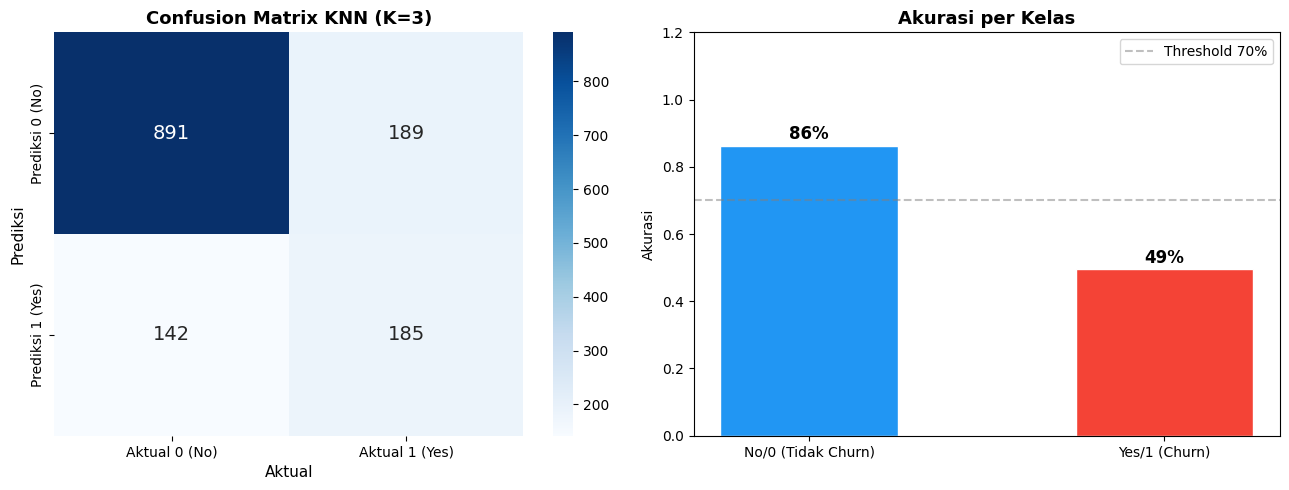

In [ ]:
# Confusion matrix
prediksi_biner = np.array(hasil_prediksi)
aktual_biner = y_test_biner.values

TP = int(np.sum((prediksi_biner == 1) & (aktual_biner == 1)))
TN = int(np.sum((prediksi_biner == 0) & (aktual_biner == 0)))
FP = int(np.sum((prediksi_biner == 1) & (aktual_biner == 0)))
FN = int(np.sum((prediksi_biner == 0) & (aktual_biner == 1)))

print('CONFUSION MATRIX (0=Tidak Churn, 1=Churn):')
print(f' {"":15} | Aktual 0 | Aktual 1')
print(f' {"Prediksi 0":15} | TN = {TN:5} | FN = {FN:5}')
print(f' {"Prediksi 1":15} | FP = {FP:5} | TP = {TP:5}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Heatmap confusion matrix
matriks_cm = np.array([[TN, FN], [FP, TP]])
sns.heatmap(matriks_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Aktual 0 (No)', 'Aktual 1 (Yes)'],
            yticklabels=['Prediksi 0 (No)', 'Prediksi 1 (Yes)'],
            ax=axes[0], annot_kws={'size': 14})
axes[0].set_title('Confusion Matrix KNN (K=3)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Prediksi', fontsize=11)
axes[0].set_xlabel('Aktual', fontsize=11)

# Bar chart akurasi per kelas
jumlah_benar_per_kelas = [TN, TP]
jumlah_total_per_kelas = [TN+FP, FN+TP]
akurasi_per_kelas = [b/t if t > 0 else 0 for b, t in zip(jumlah_benar_per_kelas, jumlah_total_per_kelas)]

batang = axes[1].bar(
    ['No/0 (Tidak Churn)', 'Yes/1 (Churn)'],
    akurasi_per_kelas,
    color=['#2196F3', '#F44336'], width=0.5, edgecolor='white'
)

for bar, nilai_akurasi in zip(batang, akurasi_per_kelas):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{nilai_akurasi*100:.0f}%', ha='center', fontweight='bold', fontsize=12)

axes[1].set_title('Akurasi per Kelas', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Akurasi')
axes[1].set_ylim(0, 1.2)
axes[1].axhline(y=0.7, color='gray', linestyle='--', alpha=0.5, label='Threshold 70%')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
accuracy  = (TP + TN) / (TP + TN + FP + FN)
recall    = TP / (TP + FN)
precision = TP / (TP + FP)
f1_score  = 2 * (precision * recall) / (precision + recall)

print(f'Accuracy  : {accuracy:.4f}  ({accuracy*100:.1f}%)')
print(f'Recall    : {recall:.4f}  ({recall*100:.1f}%)')
print(f'Precision : {precision:.4f}  ({precision*100:.1f}%)')
print(f'F1-Score  : {f1_score:.4f}  ({f1_score*100:.1f}%)')


Accuracy  : 0.7647  (76.5%)
Recall    : 0.4947  (49.5%)
Precision : 0.5657  (56.6%)
F1-Score  : 0.5278  (52.8%)


## FASE 6: Deployment

### 6.1 Fungsi Prediksi untuk Data Baru


In [ ]:
# ===== 6.1 Fungsi Prediksi Data Baru =====
def predict_churn(senior_citizen, tenure_val, internet_service, contract,
                 monthly_charges, total_charges,
                 X_train=X_train, y_train=y_train,
                 feat_min=nilai_min, feat_max=nilai_max, k=3):
    """
    Prediksi kemungkinan churn untuk pelanggan baru.
    Churn: 0 = Tidak Churn, 1 = Churn

    InternetService : 0=No, 1=DSL, 2=Fiber optic
    Contract : 0=Month-to-month, 1=One year, 2=Two year
    """
    new_data = pd.DataFrame([{
        'gender': 0, # Assuming gender doesn't impact prediction for a single customer unless specified
        'SeniorCitizen': senior_citizen,
        'tenure': tenure_val,
        'InternetService': internet_service,
        'Contract': contract,
        'MonthlyCharges': monthly_charges,
        'TotalCharges': total_charges
    }])

    new_norm = normalisasi_minmax(new_data, feat_min, feat_max)
    new_point = new_norm.iloc[0].values

    distances = []
    for j in range(len(X_train)):
        d = hitung_euclidean(new_point, X_train.iloc[j].values)
        distances.append((j+1, d, y_train.iloc[j]))

    distances_sorted = sorted(distances, key=lambda x: x[1])
    k_neighbors = distances_sorted[:k]
    votes = [n[2] for n in k_neighbors]
    vote_count = Counter(votes)

    prediction = vote_count.most_common(1)[0][0]
    prob_churn = votes.count(1) / k

    return {
        'prediksi': prediction,
        'label': 'Churn' if prediction == 1 else 'Tidak Churn',
        'probabilitas_churn': f'{prob_churn*100:.0f}%',
        'voting': dict(vote_count)
    }

print(' Fungsi predict_churn() siap digunakan!')
print(' Parameter: senior_citizen, tenure_val, internet_service (0/1/2), contract (0/1/2),')
print(' monthly_charges, total_charges')

 Fungsi predict_churn() siap digunakan!
 Parameter: senior_citizen, tenure_val, internet_service (0/1/2), contract (0/1/2),
 monthly_charges, total_charges


In [ ]:
# ===== 6.2 Contoh Prediksi Pelanggan Baru =====
print('CONTOH PREDIKSI PELANGGAN BARU')
print('='*50)

# Pelanggan A: tenure pendek, Fiber optic, Month-to-month, tagihan tinggi
result1 = predict_churn(senior_citizen=0, tenure_val=2,
                       internet_service=2, contract=0,
                       monthly_charges=95.5, total_charges=191.0)

print('\nPelanggan A:')
print(f' Senior Citizen : 0 (Bukan senior)')
print(f' Tenure : 2 bulan')
print(f' Internet Service : 2 (Fiber optic)')
print(f' Contract : 0 (Month-to-month)')
print(f' Monthly Charges : $95.5')
print(f' Total Charges : $191.0')
print(f' Prediksi : {result1["prediksi"]} ({result1["label"]})')
print(f' Prob Churn : {result1["probabilitas_churn"]}')
print(f' Voting K-3 : {result1["voting"]} (0=Tidak Churn, 1=Churn)')

# Pelanggan B: tenure panjang, DSL, Two year, tagihan rendah
result2 = predict_churn(senior_citizen=0, tenure_val=60,
                       internet_service=1, contract=2,
                       monthly_charges=25.0, total_charges=1500.0)

print('\nPelanggan B:')
print(f' Senior Citizen : 0 (Bukan senior)')
print(f' Tenure : 60 bulan')
print(f' Internet Service : 1 (DSL)')
print(f' Contract : 2 (Two year)')
print(f' Monthly Charges : $25.0')
print(f' Total Charges : $1500.0')
print(f' Prediksi : {result2["prediksi"]} ({result2["label"]})')
print(f' Prob Churn : {result2["probabilitas_churn"]}')
print(f' Voting K-5 : {result2["voting"]} (0=Tidak Churn, 1=Churn)')

CONTOH PREDIKSI PELANGGAN BARU

Pelanggan A:
 Senior Citizen : 0 (Bukan senior)
 Tenure : 2 bulan
 Internet Service : 2 (Fiber optic)
 Contract : 0 (Month-to-month)
 Monthly Charges : $95.5
 Total Charges : $191.0
 Prediksi : 1 (Churn)
 Prob Churn : 100%
 Voting K-3 : {np.int64(1): 3} (0=Tidak Churn, 1=Churn)

Pelanggan B:
 Senior Citizen : 0 (Bukan senior)
 Tenure : 60 bulan
 Internet Service : 1 (DSL)
 Contract : 2 (Two year)
 Monthly Charges : $25.0
 Total Charges : $1500.0
 Prediksi : 0 (Tidak Churn)
 Prob Churn : 0%
 Voting K-5 : {np.int64(0): 3} (0=Tidak Churn, 1=Churn)
